# 01 · Phase equilibrium and vapour-liquid equilibrium

Distillation, flash and absorption all rest on one question: at a given temperature and pressure, what
vapour is in equilibrium with a given liquid? For ideal mixtures Raoult's law answers with vapour pressures
alone; for the mixtures that matter - alcohols and water, ketones and hydrocarbons - activity coefficients
bend the answer, sometimes into an azeotrope. This notebook builds T-x-y and x-y diagrams for both cases,
fits the Wilson model against data, and locates azeotropes.

**What you will learn**
- construct T-x-y and x-y diagrams for ideal and non-ideal binaries
- use activity coefficients and the Wilson model
- locate azeotropes and understand their origin
- see the effect of pressure on VLE

**Before you start:** notebook 00  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engsep import datasets, vle
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Raoult's law and the ideal binary

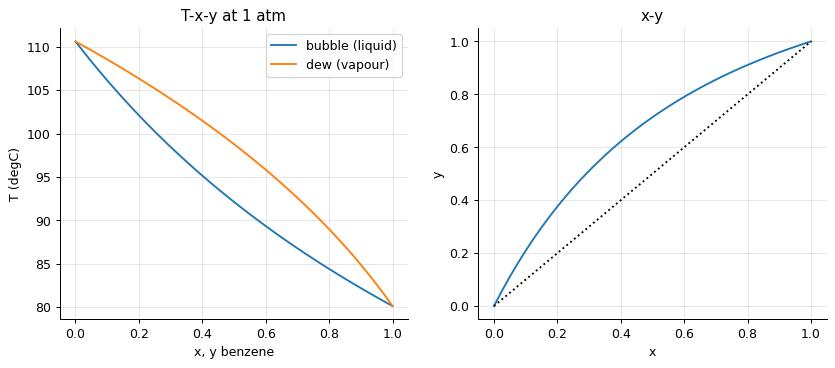

x = 0.2: bubble point 102.1 degC, y = 0.376, alpha = 2.41
x = 0.5: bubble point 92.1 degC, y = 0.714, alpha = 2.49
x = 0.8: bubble point 84.4 degC, y = 0.911, alpha = 2.56


In [2]:
pair = ("benzene", "toluene")
d = vle.Txy(pair, n=41, ideal=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].plot(d["x"], d["T"] - 273.15, label="bubble (liquid)"); ax[0].plot(d["y"], d["T"] - 273.15, label="dew (vapour)"); ax[0].set(xlabel="x, y benzene", ylabel="T (degC)", title="T-x-y at 1 atm"); ax[0].legend()
ax[1].plot(d["x"], d["y"]); ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set(xlabel="x", ylabel="y", title="x-y"); plt.show()
for x1 in (0.2, 0.5, 0.8):
    T, y = vle.bubble_y(pair, x1, ideal=True)
    print(f"x = {x1}: bubble point {T-273.15:.1f} degC, y = {y:.3f}, alpha = {vle.relative_volatility(pair, T, ideal=True):.2f}")

For an ideal pair the bubble and dew curves form a lens between the two boiling points, and the relative
volatility - the ratio of vapour pressures - is nearly constant (2.3 to 2.6 across the range). A constant α
makes the equilibrium curve a one-parameter formula, $y = \alpha x/(1 + (\alpha - 1)x)$, which is why so much
of distillation theory is written in terms of it.

## Non-ideal mixtures: the Wilson model

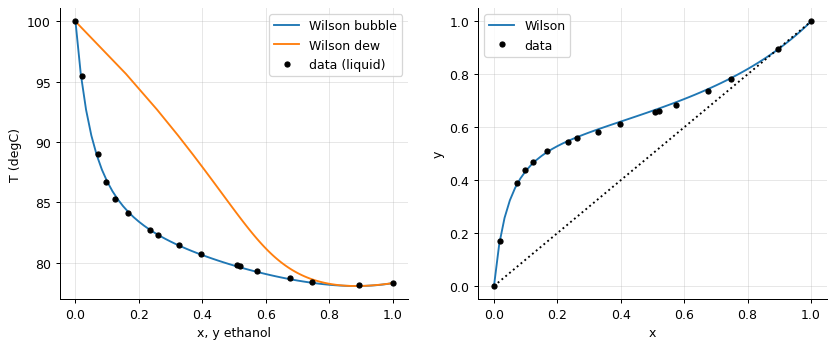

Wilson vs data: mean |dy| = 0.0056, max 0.0108


In [3]:
pair = ("ethanol", "water")
data = pd.read_csv(datasets.path("vle_ethanol_water.csv"), comment="#")
model = vle.Txy(pair, n=61)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].plot(model["x"], model["T"] - 273.15, label="Wilson bubble"); ax[0].plot(model["y"], model["T"] - 273.15, label="Wilson dew"); ax[0].plot(data.x_ethanol, data.T_C, "ko", ms=4, label="data (liquid)"); ax[0].set(xlabel="x, y ethanol", ylabel="T (degC)"); ax[0].legend()
ax[1].plot(model["x"], model["y"], label="Wilson"); ax[1].plot(data.x_ethanol, data.y_ethanol, "ko", ms=4, label="data"); ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set(xlabel="x", ylabel="y"); ax[1].legend(); plt.show()
err = np.abs(np.interp(data.x_ethanol, model["x"], model["y"]) - data.y_ethanol)
print(f"Wilson vs data: mean |dy| = {err.mean():.4f}, max {err.max():.4f}")

Ethanol-water is far from ideal: the vapour is much richer in ethanol than Raoult's law predicts at low
concentration, and the curves cross the diagonal at the azeotrope. The Wilson equation, with two parameters
fitted to the data, reproduces the whole curve within a few thousandths in $y$ - good enough for column
design, and a demonstration that the activity coefficient is the whole story of non-ideality here.

## Activity coefficients

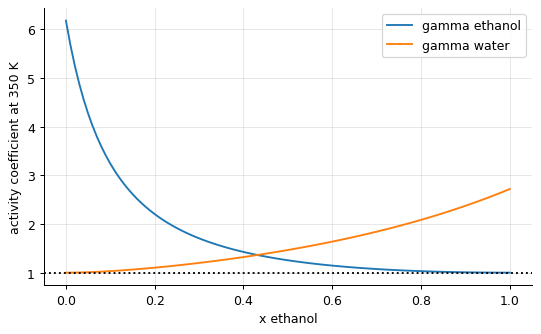

infinite-dilution activity coefficients: ethanol in water 6.18, water in ethanol 2.72


In [4]:
x = np.linspace(0, 1, 101)
g1, g2 = vle.wilson_gamma(pair, x, 350.0)
plt.plot(x, g1, label="gamma ethanol"); plt.plot(x, g2, label="gamma water"); plt.axhline(1, color="k", ls=":"); plt.xlabel("x ethanol"); plt.ylabel("activity coefficient at 350 K"); plt.legend(); plt.show()
print(f"infinite-dilution activity coefficients: ethanol in water {g1[0]:.2f}, water in ethanol {g2[-1]:.2f}")

Each component behaves ideally in its own pure liquid ($\gamma$ = 1) and most non-ideally at infinite
dilution, where an ethanol molecule is surrounded by water it would rather not be in ($\gamma^\infty \approx 6$).
Positive deviations from Raoult's law - $\gamma > 1$ - raise the vapour pressure of the mixture and, if
large enough, produce a minimum-boiling azeotrope.

## Azeotropes

In [5]:
for c1, c2 in (("ethanol", "water"), ("2-propanol", "water"), ("acetone", "methanol"), ("methanol", "water"), ("acetone", "water"), ("benzene", "toluene")):
    az = vle.azeotrope(c1, c2)
    print(f"{c1}-{c2:<10}: " + (f"{az['kind']} azeotrope at x = {az['x']:.3f}, {az['T']-273.15:.1f} degC" if az else "no azeotrope"))

ethanol-water     : minimum-boiling azeotrope at x = 0.885, 78.1 degC
2-propanol-water     : minimum-boiling azeotrope at x = 0.718, 80.4 degC
acetone-methanol  : minimum-boiling azeotrope at x = 0.794, 55.4 degC
methanol-water     : no azeotrope
acetone-water     : no azeotrope
benzene-toluene   : no azeotrope


The azeotrope is where the equilibrium curve crosses the diagonal: the vapour has the liquid's composition
and boiling changes nothing. Ethanol cannot be distilled past 89 mol % (96 wt %) at 1 atm - the reason for
molecular sieves and entrainers in fuel-ethanol plants. The library locates azeotropes by finding the
crossing, and reports none for methanol-water, which is non-ideal but not enough to cross.

## Pressure changes everything

In [6]:
for P_atm in (0.2, 1.0, 5.0):
    az = vle.azeotrope("ethanol", "water", P=P_atm * 101325.0)
    a_bt = vle.geometric_mean_alpha(("benzene", "toluene"), P=P_atm * 101325.0, ideal=True)
    print(f"{P_atm:4.1f} atm: ethanol-water azeotrope at x = {az['x']:.3f} ({az['T']-273.15:.0f} degC); benzene-toluene alpha = {a_bt:.2f}")

 0.2 atm: ethanol-water azeotrope at x = 0.847 (42 degC); benzene-toluene alpha = 2.97
 1.0 atm: ethanol-water azeotrope at x = 0.885 (78 degC); benzene-toluene alpha = 2.47
 5.0 atm: ethanol-water azeotrope at x = 0.955 (125 degC); benzene-toluene alpha = 2.06


Lower pressure lowers the boiling points, raises the relative volatility (vapour pressures diverge at low
temperature) and shifts the ethanol azeotrope towards pure ethanol - which is why vacuum columns separate
better and why pressure-swing distillation can break some azeotropes. Pressure is the designer's free
variable in VLE.

## Inside the algorithm: modified Raoult's law

In [7]:
x1_, T_ = 0.3, 355.0
g1_, g2_ = vle.wilson_gamma(("ethanol", "water"), x1_, T_)
P_ = x1_ * g1_ * vle.antoine_pressure("ethanol", T_) + (1 - x1_) * g2_ * vle.antoine_pressure("water", T_)
print("by hand: bubble pressure", P_, "Pa; y1 =", x1_ * g1_ * vle.antoine_pressure("ethanol", T_) / P_)

by hand: bubble pressure 101656.78784365463 Pa; y1 = 0.5800786401498051


## Exercises
1. Fit a one-parameter Margules model (ln gamma_1 = A x_2^2, ln gamma_2 = A x_1^2) to the ethanol-water data by least squares on y and compare its x-y curve and azeotrope with Wilson's. Where does the simpler model fail?
2. For acetone-methanol (a minimum-boiling azeotrope), compute the azeotrope composition at 0.5, 1, 2 and 5 atm and explain how pressure-swing distillation could separate the pair.
3. **Implement it yourself:** write the Wilson activity-coefficient equations from the Lambda parameters and reproduce `vle.wilson_gamma` for ethanol-water at x = 0.2 and 350 K.